## Task 2.1 

In [1]:
import numpy as np
import torch
torch.set_default_dtype(torch.float64)  # for task 2.4

mu = 5
m = 1
k = 500

def exact_solution(t):
    """
    Generate the exact solution for the damped harmonic oscillator.
    """
    delta = mu/(2*m)
    w_0 = torch.sqrt(torch.tensor(k)) # only bc m = 1, otherwise w_0 = torch.sqrt(torch.tensor(k/m))
    w = torch.sqrt(w_0**2 - delta**2)
    phi = torch.atan(-delta/w)
    A = 1/(2*torch.cos(phi))
    return torch.exp(-delta*t)*(2*A*torch.cos(w*t + phi))

def data_generator(n_samples=10, t_max=0.5):
    """
    Generate data for the damped harmonic oscillator.
    """
    t = torch.linspace(0, t_max, n_samples + 2)[1:-1].reshape(-1, 1)
    x = exact_solution(t)
    return t, x

### Plotting data

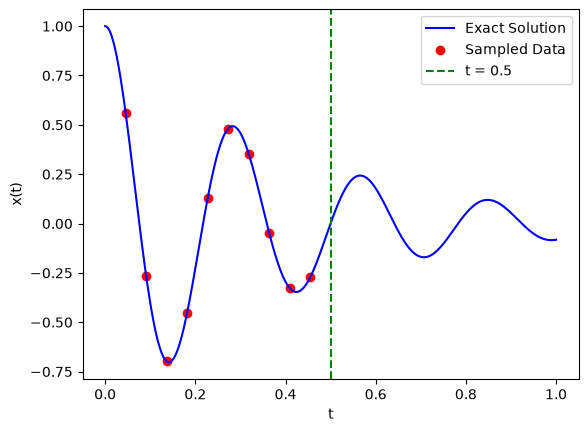

In [2]:
import matplotlib.pyplot as plt

t_data, x_data = data_generator(n_samples=10, t_max=0.5)

# Dense sampling of the exact solution for plotting
t_full = torch.linspace(0, 1.0, 500).reshape(-1, 1)
x_full = exact_solution(t_full)

plt.plot(t_full, x_full, label='Exact Solution', color='blue')
plt.scatter(t_data, x_data, color='red', label='Sampled Data')
plt.axvline(x=0.5, color='green', linestyle='--', label='t = 0.5')
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.show()

## 2.2: FFNN

### Network init

In [3]:
# nn module 
class Net(torch.nn.Module):
    def __init__(self, indim=1, outdim=1):
        super(Net, self).__init__()
        self.actf = torch.tanh
        self.lin1 = torch.nn.Linear(indim, 100)
        self.lin2 = torch.nn.Linear(100, outdim)
    # ffnn
    def forward(self, x):
        x = self.lin1(x)
        x =self.lin2(self.actf(x))
        return x


### Training and plotting

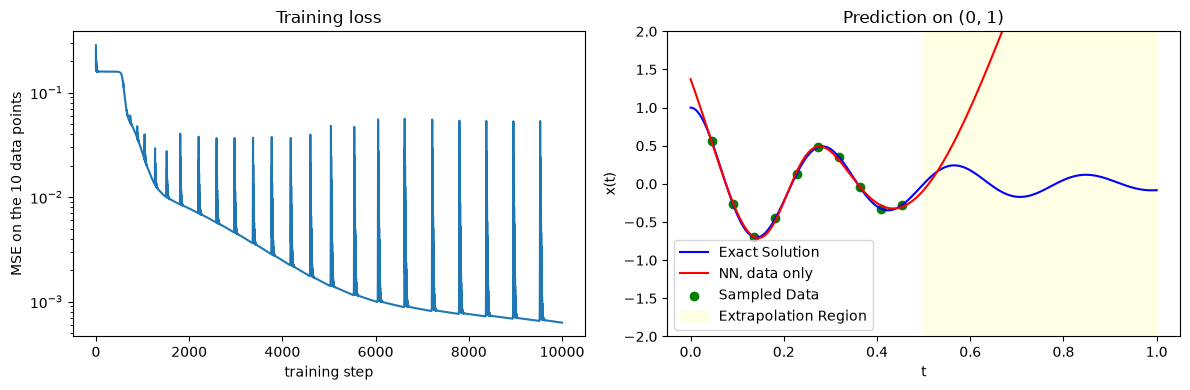

Training loss (MSE on the 10 data points) after 10000 steps:
  start 2.85e-01  ->  final 6.28e-04   (lowest 6.28e-04 at step 9999)
  final RMSE = 0.025  (typical miss at a data point; the data range from -0.70 to 0.56)


In [11]:
#Training loop
torch.manual_seed(42)
net = Net()
criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=1e-2) #1e-2 in 10.000 steps, 1e-3 needs 20.000 steps - but gives a smoother curve  

#Losses
losses = []
for step in range(10000):
    optimizer.zero_grad()
    loss = criterion(net(t_data), x_data)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

with torch.no_grad():
    x_pred = net(t_full) #Turning  off gradient tracking for plotting

#Plotting
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].semilogy(losses)
axes[0].set_xlabel('training step'); axes[0].set_ylabel('MSE on the 10 data points')
axes[0].set_title('Training loss')

axes[1].plot(t_full, x_full, label='Exact Solution', color='blue')
axes[1].plot(t_full, x_pred, label='NN, data only', color='red')
axes[1].scatter(t_data, x_data, color='green', label='Sampled Data')
axes[1].axvspan(0.5, 1.0, color='yellow', alpha=0.1, label='Extrapolation Region')
axes[1].set_ylim(-2, 2); axes[1].set_xlabel('t'); axes[1].set_ylabel('x(t)')
axes[1].set_title('Prediction on (0, 1)'); axes[1].legend()
plt.tight_layout(); plt.show()

best = min(losses)
print(f"Training loss (MSE on the {len(t_data)} data points) after {len(losses)} steps:")
print(f"  start {losses[0]:.2e}  ->  final {losses[-1]:.2e}   (lowest {best:.2e} at step {losses.index(best)})")
print(f"  final RMSE = {losses[-1]**0.5:.3f}  (typical miss at a data point; "
      f"the data range from {x_data.min().item():.2f} to {x_data.max().item():.2f})")

### Plot for error over time.


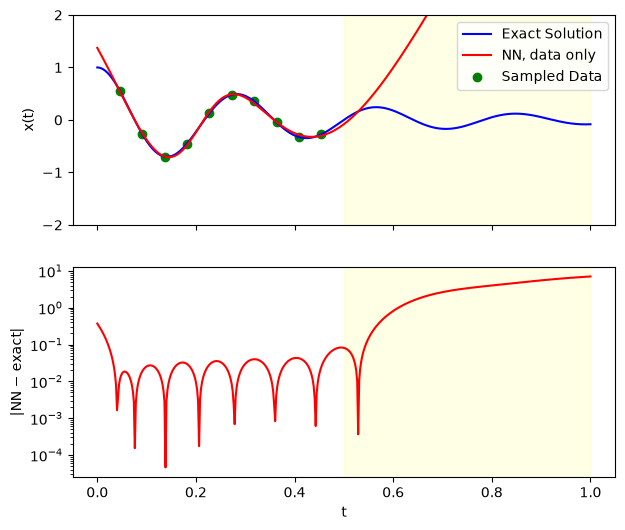

Error |NN - exact| on the 500-point grid:
  [0, 0.045)  before the first data point    RMSE = 0.174   max = 0.373 at t = 0.00
  [0.045, 0.455]  between the data points    RMSE = 0.025   max = 0.043 at t = 0.40
  (0.455, 1]  after the last data point      RMSE = 3.797   max = 7.073 at t = 1.00
  -> after the data the error is 152x larger than between the data points


In [5]:

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

ax1.plot(t_full, x_full, label='Exact Solution', color='blue')
ax1.plot(t_full, x_pred, label='NN, data only', color='red')
ax1.scatter(t_data, x_data, color='green', label='Sampled Data')
ax1.set_ylim(-2, 2); ax1.set_ylabel('x(t)'); ax1.legend()

ax2.semilogy(t_full, (x_pred - x_full).abs(), color='red')
ax2.set_xlabel('t'); ax2.set_ylabel('|NN − exact|')

for ax in (ax1, ax2):
    ax.axvspan(0.5, 1.0, color='yellow', alpha=0.1)
plt.show()

err = (x_pred - x_full).abs()[:, 0]
t = t_full[:, 0]
first, last = t_data.min().item(), t_data.max().item()
regions = {
    f"[0, {first:.3f})  before the first data point": t < first,
    f"[{first:.3f}, {last:.3f}]  between the data points": (t >= first) & (t <= last),
    f"({last:.3f}, 1]  after the last data point": t > last,
}
print("Error |NN - exact| on the 500-point grid:")
rmse = {}
for name, mask in regions.items():
    e = err[mask]
    rmse[name] = e.pow(2).mean().sqrt().item()
    print(f"  {name:42s} RMSE = {rmse[name]:.3f}   max = {e.max().item():.3f} at t = {t[mask][e.argmax()].item():.2f}")
r_between, r_after = list(rmse.values())[1], list(rmse.values())[2]
print(f"  -> after the data the error is {r_after / r_between:.0f}x larger than between the data points")


### extrapolotion interpretation

The network fits the 10 data points closely. The training loss drops from about 0.16 to 5.8·10⁻⁴, so the prediction is typically within about 0.02 of each data point, and between the data points it follows the exact solution well. After the last data point, around t = 0.46, the prediction starts to drift away from the exact solution, and by t = 1 it is far off: the error there is roughly 150 times larger than between the data points. It also starts a little too high at t = 0 (about 1.4 instead of 1), since there is no data point there either.


This happens because the loss only compares the network with the data at the 10 training times, all within (0, 0.5). As long as the curve passes close to those points the loss is low, whatever happens later. So for t > 0.5 the network has to extrapolate, and it continues the curve in a way that suits its own shape rather than the physics. The data show the first part of the motion, but nothing in them tells the network that the oscillation carries on and slowly dies out.


To do better on (0.5, 1), the network needs some information about that part of the domain. One option is more data there. Another is to use what we know about the system: The diffential equation must hold every x at every time t, and we can check it without knowing the solution. Adding it as an extra loss term at points across (0, 1), together with the initial conditions, gives the network guidance where there is no data. In other words, let's cook up a PINN baby!

## 2.3: physics-informed loss function


### Step 1: the network and its time derivatives (Task 1.1)

Our `Net`, written out. $j = 1, \dots, 100$ runs over the hidden units; `lin1` holds $W^{(1)}, b^{(1)}$ and `lin2` holds $W^{(2)}, b^{(2)}$:

$$a_j = W^{(1)}_j\, t + b^{(1)}_j, \qquad z_j = \tanh(a_j), \qquad x(t) = \sum_j W^{(2)}_j z_j + b^{(2)}$$

Differentiating with respect to $t$ uses $\partial a_j/\partial t = W^{(1)}_j$ and the tanh rules
$$\tanh' = 1 - \tanh^2, \qquad \tanh'' = -2\tanh\cdot\tanh', \qquad \tanh''' = -2\tanh'\,(1 - 3\tanh^2)$$
and gives
$$\dot x(t) = \sum_j W^{(2)}_j W^{(1)}_j \tanh'(a_j), \qquad \ddot x(t) = \sum_j W^{(2)}_j \big(W^{(1)}_j\big)^2 \tanh''(a_j).$$

### Step 2: the three loss terms

With the 10 data points $(t_i, x_i)$, $N_c = 60$ collocation points $t_c$ spread over $[0, 1]$, and $m = 1$:

- **Data**, the same MSE as in 2.2:
$$\mathcal L_{\text{data}} = \frac{1}{10}\sum_i \Big(\sum_j W^{(2)}_j \tanh\big(W^{(1)}_j t_i + b^{(1)}_j\big) + b^{(2)} - x_i\Big)^2$$
- **Physics.** At each collocation point, how far eq. 2 is from holding:
$$r(t) = \ddot x + \mu\dot x + k x = \sum_j W^{(2)}_j\Big[\big(W^{(1)}_j\big)^2 \tanh''(a_j) + \mu W^{(1)}_j \tanh'(a_j) + k\tanh(a_j)\Big] + k\,b^{(2)}, \qquad \mathcal L_{\text{phys}} = \frac{1}{N_c}\sum_c r(t_c)^2$$
- **Initial conditions.** At $t = 0$ we have $a_j = b^{(1)}_j$:
$$\mathcal L_{\text{IC}} = \big(x(0) - 1\big)^2 + \dot x(0)^2 = \Big(\sum_j W^{(2)}_j \tanh\big(b^{(1)}_j\big) + b^{(2)} - 1\Big)^2 + \Big(\sum_j W^{(2)}_j W^{(1)}_j \tanh'\big(b^{(1)}_j\big)\Big)^2$$

$$\mathcal L = \mathcal L_{\text{data}} + \lambda_{\text{phys}}\mathcal L_{\text{phys}} + \lambda_{\text{IC}}\mathcal L_{\text{IC}}$$

### Step 3: the gradients, split into an outer and an inner part

The loss only "sees" the weights through three numbers at each point: $x$, $\dot x$ and $\ddot x$. So for any weight $w$ the chain rule gives
$$\frac{\partial\mathcal L}{\partial w} = \sum_{\text{points}}\Big[\underbrace{\frac{\partial\mathcal L}{\partial x}}_{\text{outer}}\underbrace{\frac{\partial x}{\partial w}}_{\text{inner}} + \frac{\partial\mathcal L}{\partial\dot x}\frac{\partial\dot x}{\partial w} + \frac{\partial\mathcal L}{\partial\ddot x}\frac{\partial\ddot x}{\partial w}\Big].$$

**Outer part**: how the loss changes with $x$, $\dot x$, $\ddot x$ at each point. This only depends on the loss:

| point | $\partial\mathcal L/\partial x$ | $\partial\mathcal L/\partial\dot x$ | $\partial\mathcal L/\partial\ddot x$ |
|---|---|---|---|
| data point $t_i$ | $2(x(t_i) - x_i)/10$ | 0 | 0 |
| collocation point $t_c$ | $2\lambda_{\text{phys}}\,k\, r(t_c)/N_c$ | $2\lambda_{\text{phys}}\,\mu\, r(t_c)/N_c$ | $2\lambda_{\text{phys}}\, r(t_c)/N_c$ |
| $t = 0$ | $2\lambda_{\text{IC}}(x(0) - 1)$ | $2\lambda_{\text{IC}}\,\dot x(0)$ | 0 |

**Inner part**: how $x$, $\dot x$, $\ddot x$ change with each weight. This only depends on the network.
- $W^{(2)}_j$ appears as a plain factor, so you just drop it.
- $W^{(1)}_j$ appears both as a factor and inside $a_j$ (with $\partial a_j/\partial W^{(1)}_j = t$), so it needs the product rule:

| | $\partial/\partial W^{(2)}_j$ | $\partial/\partial W^{(1)}_j$ | $\partial/\partial b^{(1)}_j$ | $\partial/\partial b^{(2)}$ |
|---|---|---|---|---|
| $x$ | $\tanh(a_j)$ | $W^{(2)}_j\, t\tanh'(a_j)$ | $W^{(2)}_j \tanh'(a_j)$ | 1 |
| $\dot x$ | $W^{(1)}_j \tanh'(a_j)$ | $W^{(2)}_j\big[\tanh'(a_j) + W^{(1)}_j t \tanh''(a_j)\big]$ | $W^{(2)}_j W^{(1)}_j \tanh''(a_j)$ | 0 |
| $\ddot x$ | $\big(W^{(1)}_j\big)^2 \tanh''(a_j)$ | $W^{(2)}_j\big[2W^{(1)}_j \tanh''(a_j) + \big(W^{(1)}_j\big)^2 t \tanh'''(a_j)\big]$ | $W^{(2)}_j \big(W^{(1)}_j\big)^2 \tanh'''(a_j)$ | 0 |

Multiplying outer by inner and summing over all points gives the two gradients the task asks for:
$$\frac{\partial\mathcal L}{\partial W^{(2)}_j} = \sum_n \Big[\frac{\partial\mathcal L}{\partial x_n}\tanh(a_{nj}) + \frac{\partial\mathcal L}{\partial\dot x_n} W^{(1)}_j \tanh'(a_{nj}) + \frac{\partial\mathcal L}{\partial\ddot x_n}\big(W^{(1)}_j\big)^2 \tanh''(a_{nj})\Big]$$
$$\frac{\partial\mathcal L}{\partial W^{(1)}_j} = W^{(2)}_j \sum_n \Big[\frac{\partial\mathcal L}{\partial x_n} t_n \tanh'(a_{nj}) + \frac{\partial\mathcal L}{\partial\dot x_n}\big(\tanh'(a_{nj}) + W^{(1)}_j t_n \tanh''(a_{nj})\big) + \frac{\partial\mathcal L}{\partial\ddot x_n}\big(2W^{(1)}_j \tanh''(a_{nj}) + \big(W^{(1)}_j\big)^2 t_n \tanh'''(a_{nj})\big)\Big]$$

The bias columns of the table give $\partial\mathcal L/\partial b^{(1)}$ and $\partial\mathcal L/\partial b^{(2)}$ the same way. The task doesn't ask for them, but training in 2.5 needs them.

Two checks:
- **Week 1 backprop is the special case.** With only the data term (outer $\dot x$ and $\ddot x$ columns zero), this is exactly the week 1 result: $\partial\mathcal L/\partial W^{(2)}_j$ is "error times $z_j$".
- **The rows of the inner table follow from each other.** Differentiating the $x$ row with respect to $t$ gives the $\dot x$ row.

### Writing up the task 1.1 in code - checking with autograd:

In [6]:
t_col = torch.linspace(0, 1, 60).reshape(-1, 1)    # collocation points for L_phys
t_zero = torch.zeros(1, 1)                         # where the initial conditions are enforced
N_data, N_col = len(t_data), len(t_col)

def x_and_derivatives(net, t):
    W1 = net.lin1.weight[:, 0]   # (100,)
    b1 = net.lin1.bias           # (100,)
    W2 = net.lin2.weight[0]      # (100,)
    b2 = net.lin2.bias           # (1,)
    a = t * W1 + b1              # (N, 100): a_j at every time
    z = torch.tanh(a)
    x    = z @ W2 + b2
    x_t  = (W1 * (1 - z**2)) @ W2                       # sum_j W2_j W1_j tanh'(a_j)
    x_tt = (W1**2 * (-2 * z * (1 - z**2))) @ W2         # sum_j W2_j W1_j^2 tanh''(a_j)
    return x, x_t, x_tt

def derivatives_autograd(model, t):
    t = t.clone().requires_grad_(True)
    x = model(t)
    x_t  = torch.autograd.grad(x, t, torch.ones_like(x), create_graph=True)[0]
    x_tt = torch.autograd.grad(x_t, t, torch.ones_like(x_t), create_graph=True)[0]
    return x, x_t, x_tt

# check against autograd
x_a, xt_a, xtt_a = derivatives_autograd(net, t_full)
with torch.no_grad():
    x, x_t, x_tt = x_and_derivatives(net, t_full)
print('max diff dx/dt   :', (x_t - xt_a[:, 0]).abs().max().item())
print('max diff d2x/dt2 :', (x_tt - xtt_a[:, 0]).abs().max().item())

max diff dx/dt   : 1.7763568394002505e-14
max diff d2x/dt2 : 1.4210854715202004e-13


### The loss and its gradients by hand:

In [7]:
def inner_derivatives(net, t):
    """How x, dx/dt and d2x/dt2 at each time in t change with each weight (the inner table)."""
    W1 = net.lin1.weight[:, 0]
    b1 = net.lin1.bias
    W2 = net.lin2.weight[0]
    z  = torch.tanh(t * W1 + b1)
    d1 = 1 - z**2                    # 1st derivative of tanh
    d2 = -2 * z * d1                 # 2nd derivative of tanh
    d3 = -2 * d1 * (1 - 3 * z**2)    # 3rd derivative of tanh
    ones, zeros = torch.ones(len(t)), torch.zeros(len(t))
    return {
        'x':    {'W2': z,          'W1': W2 * d1 * t,                          'b1': W2 * d1,           'b2': ones},
        'x_t':  {'W2': W1 * d1,    'W1': W2 * (d1 + W1 * t * d2),              'b1': W2 * W1 * d2,      'b2': zeros},
        'x_tt': {'W2': W1**2 * d2, 'W1': W2 * (2 * W1 * d2 + W1**2 * t * d3),  'b1': W2 * W1**2 * d3,   'b2': zeros},
    }

def chain_rule(outer, inner):
    """dL/dw = sum over points of  dL/dx * dx/dw  +  dL/dx_t * dx_t/dw  +  dL/dx_tt * dx_tt/dw"""
    return {w: sum(outer[q] @ inner[q][w] for q in ['x', 'x_t', 'x_tt']) for w in ['W1', 'b1', 'W2', 'b2']}

def loss_and_gradients(net, lam_phys, lam_ic):
    with torch.no_grad():
        # the three loss terms
        x_d, _, _ = x_and_derivatives(net, t_data)
        x_c, xt_c, xtt_c = x_and_derivatives(net, t_col)
        x_0, xt_0, _ = x_and_derivatives(net, t_zero)
        r = xtt_c + mu * xt_c + k * x_c                 # residual of eq. 2 at the collocation points
        L_data = ((x_d - x_data[:, 0])**2).mean()
        L_phys = (r**2).mean()
        L_ic   = ((x_0 - 1)**2 + xt_0**2).sum()
        loss = L_data + lam_phys * L_phys + lam_ic * L_ic

        # outer table: dL/dx, dL/dx_t, dL/dx_tt at each point
        no_effect = torch.zeros(N_data)
        outer_data = {'x': 2 * (x_d - x_data[:, 0]) / N_data, 'x_t': no_effect, 'x_tt': no_effect}
        e = 2 * lam_phys * r / N_col
        outer_phys = {'x': k * e, 'x_t': mu * e, 'x_tt': e}
        outer_ic   = {'x': 2 * lam_ic * (x_0 - 1), 'x_t': 2 * lam_ic * xt_0, 'x_tt': torch.zeros(1)}

        # outer x inner for each group of points, then add the groups
        g_data = chain_rule(outer_data, inner_derivatives(net, t_data))
        g_phys = chain_rule(outer_phys, inner_derivatives(net, t_col))
        g_ic   = chain_rule(outer_ic,   inner_derivatives(net, t_zero))
        g = {w: g_data[w] + g_phys[w] + g_ic[w] for w in g_data}

    # same order and shapes as net.parameters(): lin1.weight, lin1.bias, lin2.weight, lin2.bias
    grads = [g['W1'].reshape(-1, 1), g['b1'], g['W2'].reshape(1, -1), g['b2'].reshape(1)]
    return loss, (L_data, L_phys, L_ic), grads

## Task 2.4

In [ ]:
lam_phys, lam_ic = 1e-4, 1.0
torch.manual_seed(42)
net_check = Net()
_, _, grads = loss_and_gradients(net_check, lam_phys, lam_ic)
hand = {'W1': grads[0], 'W2': grads[2]}

eps = 1e-5
fd = {}
for name, W in [('W1', net_check.lin1.weight), ('W2', net_check.lin2.weight)]:
    fd[name] = torch.zeros_like(W)
    with torch.no_grad():
        for idx in np.ndindex(*W.shape):
            original = W[idx].item()
            W[idx] = original + eps; L_plus  = loss_and_gradients(net_check, lam_phys, lam_ic)[0]
            W[idx] = original - eps; L_minus = loss_and_gradients(net_check, lam_phys, lam_ic)[0]
            W[idx] = original
            fd[name][idx] = (L_plus - L_minus) / (2 * eps)     # eq. 8

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ['W1', 'W2']):
    h, f = hand[name].flatten(), fd[name].flatten()
    ax.scatter(f, h, s=10)
    ax.plot([f.min(), f.max()], [f.min(), f.max()], color='grey', lw=0.8)
    ax.set_xlabel('finite difference'); ax.set_ylabel('hand-derived'); ax.set_title(f'dL/d{name}, all {len(h)} entries')
    print(f"dL/d{name}: relative error ||hand - FD|| / ||FD|| = {((h - f).norm() / f.norm()).item():.2e}")
plt.tight_layout(); plt.show()